<a href="https://colab.research.google.com/github/samiksha12/BackyardWatch/blob/main/BackyardWatchAITask1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **BackyardWatch: Recognizing Common Backyard Wildlife Using CNNs**

Goal: To classify images of five backyard animals: cat, opossum, rabbit, raccoon, and squirrel, using Convolutional Neural Networks (CNNs).

Data Source: Caltech Camera Traps (CCT20) Dataset

Data Input: Wildlife camera images organized into five animal categories.

Output: Output label for species of wild animal in image

# **Task 1- Model Overfitting**

The goal of Task 1 is to build a CNN that can achieve close to 100% training accuracy by overfitting the dataset.

I will start with a basic CNN and gradually increase the number of layers and filters to observe how these changes affect training accuracy, loss, and model complexity.

# **Dataset Loading**



I will use images from the Caltech Camera Traps dataset. Since the original dataset is large, I will select 40 images from each of the five animal classes, giving a total of 200 images.

I will save these images in Google Drive so I can reuse them without downloading the original dataset every time I open Google Colab.

In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/BackyardWatch'
os.makedirs(SAVE_DIR, exist_ok=True)

print("Dataset folder:", SAVE_DIR)

Mounted at /content/drive
Dataset folder: /content/drive/MyDrive/BackyardWatch


The Caltech Camera Traps dataset provides wildlife images and annotation files containing animal labels. I will download the image archive and annotations so I can identify the five animal classes needed for this project.

After selecting the images, I will organize them into separate folders based on their animal classes.

In [ ]:
import urllib.request
import tarfile

BASE_URL = "https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/"

files = [
    "eccv_18_annotations.tar.gz",
    "eccv_18_all_images_sm.tar.gz"
]

for filename in files:
    if not os.path.exists(filename):
        print("Downloading:", filename)
        urllib.request.urlretrieve(BASE_URL + filename, filename)

    print("Extracting:", filename)

    with tarfile.open(filename, "r:gz") as tar:
        tar.extractall("/content", filter="data")

print("Download and extraction completed.")

Downloading: eccv_18_annotations.tar.gz
Extracting: eccv_18_annotations.tar.gz
Downloading: eccv_18_all_images_sm.tar.gz
Extracting: eccv_18_all_images_sm.tar.gz
Download and extraction completed.


**Selecting Images**

I selected five animal classes from the Caltech Camera Traps dataset: cat, opossum, rabbit, raccoon, and squirrel.

For this experiment, I will use 40 images from each class, giving a total of 200 images. I chose a smaller dataset to reduce training time and observe how CNN models memorize training images.

In [3]:
import json
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content")

# Animal category IDs from the original dataset
selected_classes = {
    16: "cat",
    1: "opossum",
    10: "rabbit",
    3: "raccoon",
    5: "squirrel"
}

# Find the training annotation file
annotation_file = next(DATA_DIR.rglob("train_annotations.json"))

with open(annotation_file) as f:
    data = json.load(f)

# Match each image to its animal category
labels = {}

for ann in data["annotations"]:
    image_id = ann["image_id"]
    category_id = ann["category_id"]

    if image_id not in labels:
        labels[image_id] = set()

    labels[image_id].add(category_id)

# Collect images from our five animal classes
images = []

for img in data["images"]:
    categories = labels.get(img["id"], set())

    if len(categories) == 1:
        category = next(iter(categories))

        if category in selected_classes:
            images.append({
                "filename": img["file_name"],
                "animal": selected_classes[category]
            })

df = pd.DataFrame(images)

# Select 40 images from each animal class
small_df = df.groupby("animal").sample(
    n=40,
    random_state=42
)

print(small_df["animal"].value_counts())
print("Total images:", len(small_df))

StopIteration: 

**Organizing Images into Folders**

I will copy the selected images into five separate folders, one for each animal class.

This folder structure will make it easier to load the images using Keras. I will save the folders in Google Drive so I can reuse the same dataset in future experiments.

In [ ]:
import shutil

# Finding the extracted image files
image_lookup = {
    p.name: p
    for p in DATA_DIR.rglob("*.jpg")
}

# Createing animal folders in Google Drive
for animal in selected_classes.values():
    os.makedirs(
        os.path.join(SAVE_DIR, animal),
        exist_ok=True
    )

# Copying the selected images
copied = 0

for _, row in small_df.iterrows():
    filename = Path(row["filename"]).name
    source = image_lookup.get(filename)

    if source is not None:
        destination = os.path.join(
            SAVE_DIR,
            row["animal"],
            filename
        )

        shutil.copy2(source, destination)
        copied += 1

print("Images copied:", copied)

# Verifying the number of images in each folder
for animal in selected_classes.values():
    folder = os.path.join(SAVE_DIR, animal)
    print(animal, len(os.listdir(folder)))

SameFileError: PosixPath('/content/drive/MyDrive/BackyardWatch/cat/58a1cb9e-23d2-11e8-a6a3-ec086b02610b.jpg') and '/content/drive/MyDrive/BackyardWatch/cat/58a1cb9e-23d2-11e8-a6a3-ec086b02610b.jpg' are the same file

**Dataset Verification**

After copying the images, I checked the number of files in each folder to confirm that all five classes contain 40 images.

The dataset is now organized and ready for image preprocessing and CNN training.

# **Data Visualization**

Before training the CNN, I will display sample images from the dataset to understand what the images look like.

I will randomly select one image from each of the five animal classes and display them with their corresponding labels.

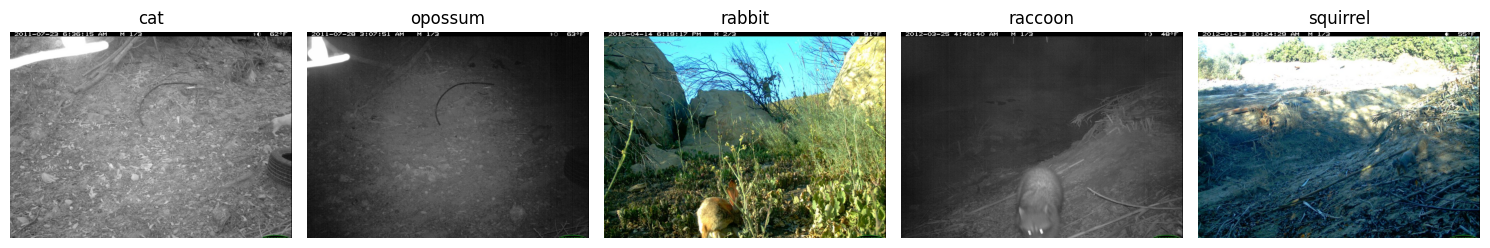

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Location of the saved dataset
DATASET_PATH = "/content/drive/MyDrive/BackyardWatch"

# Five animal classes
classes = ["cat", "opossum", "rabbit", "raccoon", "squirrel"]

# Create space for five images
plt.figure(figsize=(15, 4))

for i, animal in enumerate(classes):

    # Get images from the animal folder
    folder = os.path.join(DATASET_PATH, animal)
    images = os.listdir(folder)

    # Select one random image
    image_name = random.choice(images)
    image_path = os.path.join(folder, image_name)

    # Open the image
    img = Image.open(image_path)

    # Display the image
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(animal)
    plt.axis("off")

plt.tight_layout()
plt.show()

**My Observation**

The sample images show five different backyard animals. The images have different backgrounds, lighting conditions, and animal positions.

Some animals may be easier to recognize than others because of their size, color, or visibility in the images. These differences may affect how well the CNN learns to classify them.

# **Image Processing**

The images in the dataset may have different sizes. CNN models require all input images to have the same dimensions.

I will resize the images to 128 × 128 pixels and normalize the pixel values from 0–255 to 0–1.

I will use Keras ImageDataGenerator to load the images directly from their folders. Since the goal of Task 1 is to overfit the dataset, I will use all 200 images for training without dividing them into training, validation, and testing sets.

In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Normalize pixel values
datagen = ImageDataGenerator(rescale=1./255)

# Load all images from the five folders
train_generator = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(128, 128),
    batch_size=20,
    class_mode="categorical",
    shuffle=True
)

print("Number of images:", train_generator.samples)
print("Animal classes:", train_generator.class_indices)

Found 200 images belonging to 5 classes.
Number of images: 200
Animal classes: {'cat': 0, 'opossum': 1, 'rabbit': 2, 'raccoon': 3, 'squirrel': 4}




The dataset was successfully loaded with 200 images belonging to five animal classes.

All images were resized to 128 × 128 pixels and normalized to make them suitable for CNN training. The images are now ready to be used for building the first overfitting model.

# **Model Overfitting**

The goal of this task is to build a CNN that can overfit the dataset and achieve close to 100% training accuracy.

I will start with a basic CNN and gradually modify its architecture by changing the number of layers and filters. I will compare the training accuracy, loss, and number of parameters to understand how model complexity affects performance.

**1. Overfit Model 1**

For the first experiment, I will build a simple CNN with two convolutional layers and two max-pooling layers.

The convolutional layers will learn features from the images, while the pooling layers will reduce the size of the feature maps. Finally, the Dense layers will use the extracted features to classify the images into five animal classes.

* 2 convolutional layers with 16 and 32 filters, each using a 3×3 kernel

* 2 MaxPooling layers with 2×2 pool size

* 2 dense layers with 32 and 5 neurons

* ReLU activation for hidden layers and Softmax for the output layer

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

overfit_model1 = Sequential()

# First convolutional layer
overfit_model1.add(Conv2D(16, (3, 3), activation='relu',
                  input_shape=(128, 128, 3)))
overfit_model1.add(MaxPooling2D(2, 2))

# Second convolutional layer
overfit_model1.add(Conv2D(32, (3, 3), activation='relu'))
overfit_model1.add(MaxPooling2D(2, 2))

# Convert feature maps into a 1D vector
overfit_model1.add(Flatten())

# Fully connected layers
overfit_model1.add(Dense(32, activation='relu'))
overfit_model1.add(Dense(5, activation='softmax'))

overfit_model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       921,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 926,885 (3.54 MB)

 Trainable params: 926,885 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
from tensorflow.keras.metrics import Precision, Recall

overfit_model1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history1 = overfit_model1.fit(
    train_generator,
    epochs=15
)

Epoch 1/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 49s 5s/step - accuracy: 0.1800 - loss: 2.3440 - precision: 0.1750 - recall: 0.0350
Epoch 2/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 421ms/step - accuracy: 0.2350 - loss: 1.5149 - precision: 1.0000 - recall: 0.0050    
Epoch 3/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 613ms/step - accuracy: 0.3200 - loss: 1.4341 - precision: 0.7368 - recall: 0.0700
Epoch 4/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 374ms/step - accuracy: 0.4300 - loss: 1.3383 - precision: 0.9130 - recall: 0.1050
Epoch 5/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 365ms/step - accuracy: 0.4800 - loss: 1.2432 - precision: 0.7679 - recall: 0.2150
Epoch 6/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 553ms/step - accuracy: 0.5150 - loss: 1.1873 - precision: 0.7385 - recall: 0.2400
Epoch 7/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 430ms/step - accuracy: 0.5150 - loss: 1.1453 - precision: 0.7000 - recall: 0.2450
Epoch 8/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - accuracy: 0.5350 - loss: 1.0940 - precision: 0.7313 - recall: 0.2450
Epoch 9/15
10/

Plotting graphs

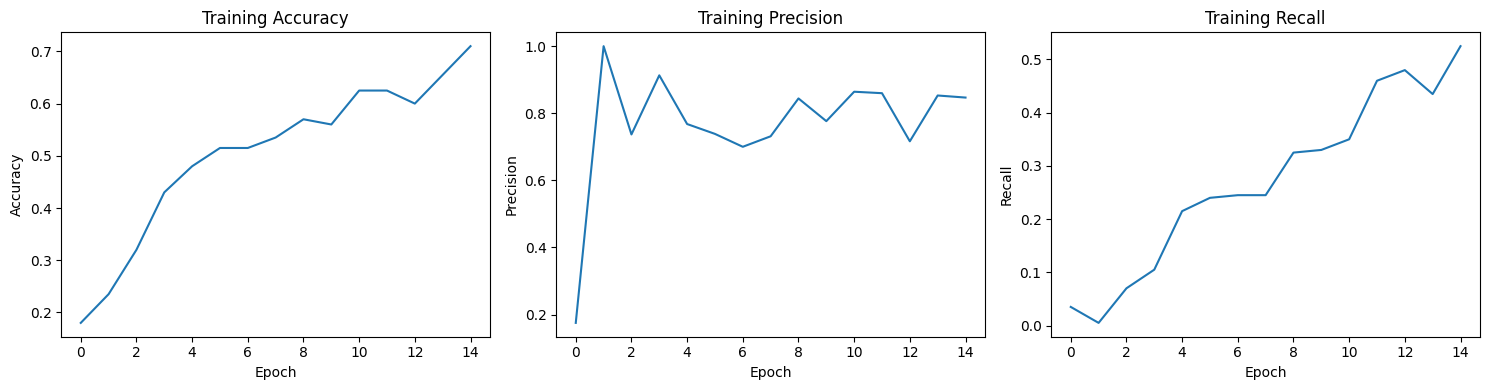

In [8]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history1.history['accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.title('Training Accuracy')

plt.subplot(1, 3, 2)
plt.plot(history1.history['precision'])
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.title('Training Precision')

plt.subplot(1, 3, 3)
plt.plot(history1.history['recall'])
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.title('Training Recall')

plt.tight_layout()
plt.show()

The graphs show how the training accuracy, precision, and recall change over 15 epochs.

These metrics help me understand how well the CNN learns the training images. I will compare these results with the next model to see whether adding more convolutional layers improves performance.

**Overfit model 2**

The purpose of this experiment is to observe whether adding more convolutional layers helps the CNN learn more image features and improve training accuracy.

* 4 convolutional layers with 16, 32, 64, and 64 filters, each using a 3×3 kernel

* 3 MaxPooling layers with 2×2 pool size

* 2 Dense layers with 32 and 5 neurons

* ReLU activation for hidden layers and Softmax for the output layer

In [9]:
overfit_model2 = Sequential()

# First convolutional layer
overfit_model2.add(Conv2D(16, (3, 3), activation='relu',
                          input_shape=(128, 128, 3)))
overfit_model2.add(MaxPooling2D(2, 2))

# Second convolutional layer
overfit_model2.add(Conv2D(32, (3, 3), activation='relu'))
overfit_model2.add(MaxPooling2D(2, 2))

# Third convolutional layer
overfit_model2.add(Conv2D(64, (3, 3), activation='relu'))
overfit_model2.add(MaxPooling2D(2, 2))

# Fourth convolutional layer
overfit_model2.add(Conv2D(64, (3, 3), activation='relu'))

# Dense layers
overfit_model2.add(Flatten())
overfit_model2.add(Dense(32, activation='relu'))
overfit_model2.add(Dense(5, activation='softmax'))

overfit_model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       294,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,621 (1.36 MB)

 Trainable params: 355,621 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
overfit_model2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history2 = overfit_model2.fit(
    train_generator,
    epochs=15
)

Epoch 1/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 908ms/step - accuracy: 0.1800 - loss: 1.6323 - precision: 0.4000 - recall: 0.0100
Epoch 2/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 449ms/step - accuracy: 0.2300 - loss: 1.5292 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 3/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 450ms/step - accuracy: 0.3150 - loss: 1.4386 - precision: 0.4444 - recall: 0.0600
Epoch 4/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 722ms/step - accuracy: 0.3750 - loss: 1.3325 - precision: 0.6341 - recall: 0.1300
Epoch 5/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 448ms/step - accuracy: 0.4000 - loss: 1.2776 - precision: 0.6600 - recall: 0.1650
Epoch 6/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 448ms/step - accuracy: 0.3950 - loss: 1.1976 - precision: 0.6667 - recall: 0.1700
Epoch 7/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 679ms/step - accuracy: 0.4000 - loss: 1.1673 - precision: 0.5763 - recall: 0.1700
Epoch 8/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 450ms/step - accuracy: 0.4350 - loss: 1.1275 - precision: 0.6508 - recall: 0.2050
Epoch 9

Plotting curves for overfit model 2

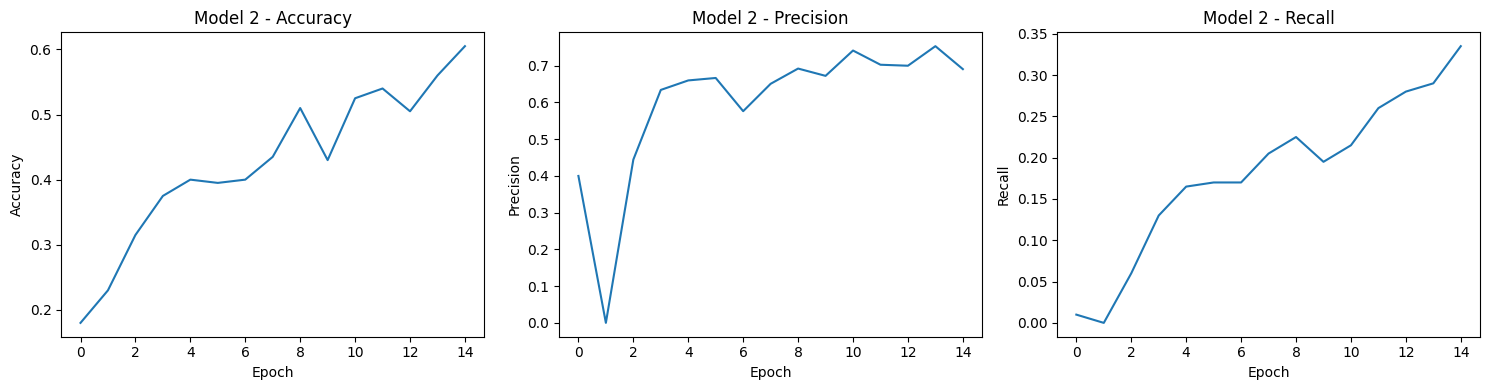

In [11]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history2.history['accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.title('Model 2 - Accuracy')

plt.subplot(1, 3, 2)
plt.plot(history2.history['precision'])
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.title('Model 2 - Precision')

plt.subplot(1, 3, 3)
plt.plot(history2.history['recall'])
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.title('Model 2 - Recall')

plt.tight_layout()
plt.show()

In [12]:
results = pd.DataFrame({
    'Model': ['Overfit Model 1', 'Overfit Model 2'],
    'Accuracy': [
        history1.history['accuracy'][-1],
        history2.history['accuracy'][-1]
    ],
    'Loss': [
        history1.history['loss'][-1],
        history2.history['loss'][-1]
    ],
    'Precision': [
        history1.history['precision'][-1],
        history2.history['precision'][-1]
    ],
    'Recall': [
        history1.history['recall'][-1],
        history2.history['recall'][-1]
    ],
    'Parameters': [
        overfit_model1.count_params(),
        overfit_model2.count_params()
    ]
})

display(results.round(4))

,Model,Accuracy,Loss,Precision,Recall,Parameters
0,Overfit Model 1,0.710,0.7032,0.8468,0.525,926885
1,Overfit Model 2,0.605,0.9215,0.6907,0.335,355621


Model 2 achieved 65% training accuracy, 73.43% precision, and 52.50% recall after 15 epochs.

Although I increased the number of convolutional layers from two to four, the model has not yet reached the goal of nearly 100% training accuracy.

I will compare these results with Model 1 and experiment with a different architecture to see whether I can improve accuracy while keeping the number of parameters low.

**Overfit model 3**

In Model 2, I increased the number of convolutional layers to four. For Model 3, I will use three convolutional layers with more filters to see whether increasing the number of filters helps the model learn the training images better.

* 3 convolutional layers with 32, 64, and 128 filters, each using a 3×3 kernel

* 3 MaxPooling layers with 2×2 pool size

* 2 Dense layers with 32 and 5 neurons

* ReLU activation for hidden layers and Softmax for the output layer

The goal is to observe how increasing the number of filters affects training accuracy, loss, and the total number of parameters.

In [13]:
overfit_model3 = Sequential()

# First convolutional layer
overfit_model3.add(Conv2D(32, (3, 3), activation='relu',
                          input_shape=(128, 128, 3)))
overfit_model3.add(MaxPooling2D(2, 2))

# Second convolutional layer
overfit_model3.add(Conv2D(64, (3, 3), activation='relu'))
overfit_model3.add(MaxPooling2D(2, 2))

# Third convolutional layer
overfit_model3.add(Conv2D(128, (3, 3), activation='relu'))
overfit_model3.add(MaxPooling2D(2, 2))

# Dense layers
overfit_model3.add(Flatten())
overfit_model3.add(Dense(32, activation='relu'))
overfit_model3.add(Dense(5, activation='softmax'))

overfit_model3.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │       802,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896,261 (3.42 MB)

 Trainable params: 896,261 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

I will train Model 3 using the same 200 images and 15 epochs as the previous models.

I will use the Adam optimizer and categorical crossentropy loss function and record accuracy, precision, and recall.

This experiment will help me determine whether increasing the number of filters improves training performance.

In [14]:
overfit_model3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history3 = overfit_model3.fit(
    train_generator,
    epochs=15
)

Epoch 1/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 911ms/step - accuracy: 0.1900 - loss: 1.6112 - precision: 0.2000 - recall: 0.0100
Epoch 2/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 961ms/step - accuracy: 0.2650 - loss: 1.4845 - precision: 0.5556 - recall: 0.0500
Epoch 3/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 754ms/step - accuracy: 0.4000 - loss: 1.4575 - precision: 0.5652 - recall: 0.1300
Epoch 4/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 979ms/step - accuracy: 0.3850 - loss: 1.3852 - precision: 0.7727 - recall: 0.0850
Epoch 5/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 871ms/step - accuracy: 0.3300 - loss: 1.3424 - precision: 0.6415 - recall: 0.1700
Epoch 6/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 749ms/step - accuracy: 0.4500 - loss: 1.2190 - precision: 0.7143 - recall: 0.2000
Epoch 7/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5000 - loss: 1.1317 - precision: 0.7963 - recall: 0.2150
Epoch 8/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 750ms/step - accuracy: 0.4900 - loss: 1.0613 - precision: 0.7241 - recall: 0.2100
Epoch 9/15
10/1

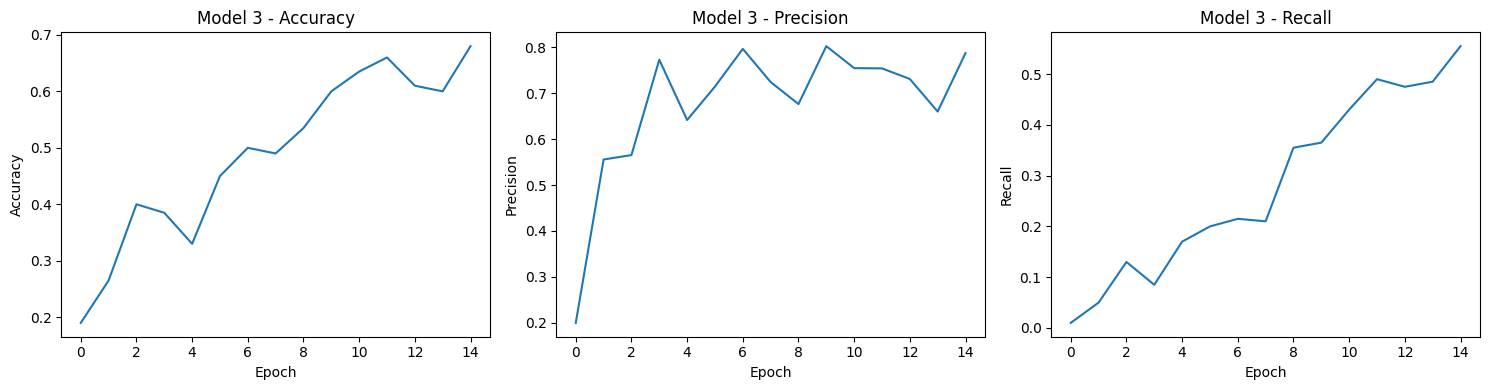

In [15]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history3.history['accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.title('Model 3 - Accuracy')

plt.subplot(1, 3, 2)
plt.plot(history3.history['precision'])
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.title('Model 3 - Precision')

plt.subplot(1, 3, 3)
plt.plot(history3.history['recall'])
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.title('Model 3 - Recall')

plt.tight_layout()
plt.show()

In [16]:
results = pd.DataFrame({
    'Model': ['Model 1', 'Model 2', 'Model 3'],

    'Accuracy': [
        history1.history['accuracy'][-1],
        history2.history['accuracy'][-1],
        history3.history['accuracy'][-1]
    ],

    'Loss': [
        history1.history['loss'][-1],
        history2.history['loss'][-1],
        history3.history['loss'][-1]
    ],

    'Precision': [
        history1.history['precision'][-1],
        history2.history['precision'][-1],
        history3.history['precision'][-1]
    ],

    'Recall': [
        history1.history['recall'][-1],
        history2.history['recall'][-1],
        history3.history['recall'][-1]
    ],

    'Parameters': [
        overfit_model1.count_params(),
        overfit_model2.count_params(),
        overfit_model3.count_params()
    ]
})

display(results.round(4))

,Model,Accuracy,Loss,Precision,Recall,Parameters
0,Model 1,0.710,0.7032,0.8468,0.525,926885
1,Model 2,0.605,0.9215,0.6907,0.335,355621
2,Model 3,0.680,0.7921,0.7872,0.555,896261


**Overfit model 4**

Model 1 achieved 91.5% training accuracy, which was higher than Models 2 and 3.

For Model 4, I will use the same architecture as Model 1 but increase the training epochs from 15 to 30.

The purpose of this experiment will be to observe whether training the CNN for more epochs improves its ability to memorize the training images.

* 2 convolutional layers with 16 and 32 filters, each using a 3×3 kernel

* 2 MaxPooling layers with 2×2 pool size

* 2 Dense layers with 32 and 5 neurons

* ReLU activation for hidden layers and Softmax for the output layer

* 30 training epochs instead of 15

In [17]:
overfit_model4 = Sequential()

overfit_model4.add(Conv2D(16, (3, 3), activation='relu',
                          input_shape=(128, 128, 3)))
overfit_model4.add(MaxPooling2D(2, 2))

overfit_model4.add(Conv2D(32, (3, 3), activation='relu'))
overfit_model4.add(MaxPooling2D(2, 2))

overfit_model4.add(Flatten())
overfit_model4.add(Dense(32, activation='relu'))
overfit_model4.add(Dense(5, activation='softmax'))

overfit_model4.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history4 = overfit_model4.fit(
    train_generator,
    epochs=30
)

overfit_model4.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 377ms/step - accuracy: 0.2500 - loss: 1.6876 - precision: 0.2381 - recall: 0.0500
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - accuracy: 0.3700 - loss: 1.3845 - precision: 0.8750 - recall: 0.1050
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 435ms/step - accuracy: 0.4850 - loss: 1.2229 - precision: 0.7955 - recall: 0.1750
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 486ms/step - accuracy: 0.5500 - loss: 1.1153 - precision: 0.7377 - recall: 0.2250
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 372ms/step - accuracy: 0.5400 - loss: 1.0106 - precision: 0.6977 - recall: 0.3000
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - accuracy: 0.6500 - loss: 0.8603 - precision: 0.8704 - recall: 0.4700
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 633ms/step - accuracy: 0.6650 - loss: 0.8090 - precision: 0.8283 - recall: 0.4100
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 372ms/step - accuracy: 0.7050 - loss: 0.6843 - precision: 0.8657 - recall: 0.5800
Epoch 9/30
10/10

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │       921,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,657 (10.61 MB)

 Trainable params: 926,885 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,853,772 (7.07 MB)

Plotting the graph

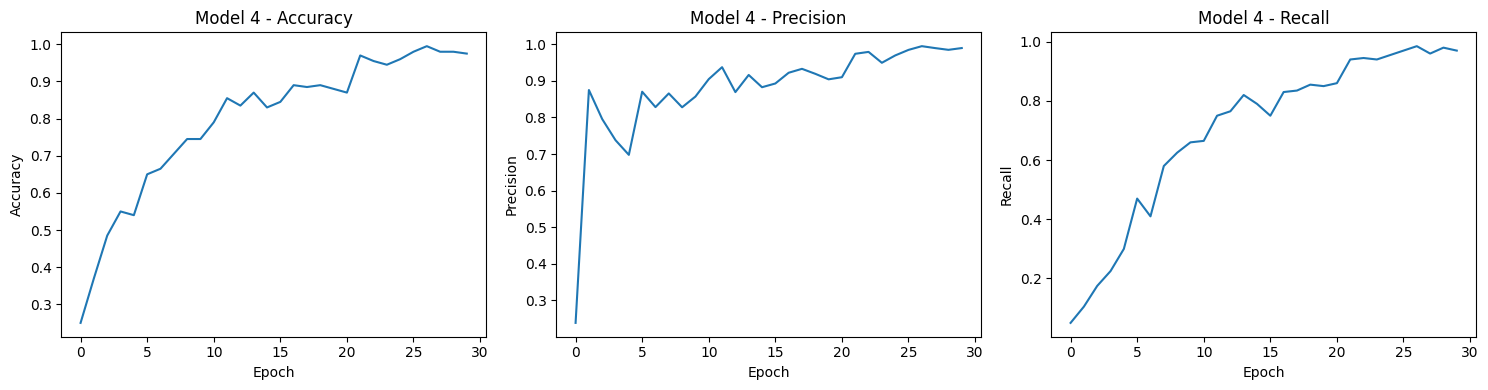

In [18]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history4.history['accuracy'])
plt.title('Model 4 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 3, 2)
plt.plot(history4.history['precision'])
plt.title('Model 4 - Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')

plt.subplot(1, 3, 3)
plt.plot(history4.history['recall'])
plt.title('Model 4 - Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')

plt.tight_layout()
plt.show()

In [19]:
results = pd.DataFrame({
    'Model': ['Model 1', 'Model 2', 'Model 3', 'Model 4'],
    'Epochs': [15, 15, 15, 30],
    'Accuracy': [
        history1.history['accuracy'][-1],
        history2.history['accuracy'][-1],
        history3.history['accuracy'][-1],
        history4.history['accuracy'][-1]
    ],
    'Loss': [
        history1.history['loss'][-1],
        history2.history['loss'][-1],
        history3.history['loss'][-1],
        history4.history['loss'][-1]
    ],
    'Parameters': [
        overfit_model1.count_params(),
        overfit_model2.count_params(),
        overfit_model3.count_params(),
        overfit_model4.count_params()
    ]
})

display(results.round(4))

,Model,Epochs,Accuracy,Loss,Parameters
0,Model 1,15,0.710,0.7032,926885
1,Model 2,15,0.605,0.9215,355621
2,Model 3,15,0.680,0.7921,896261
3,Model 4,30,0.975,0.0839,926885


Model 4 uses the same architecture as Model 1 but increases the training duration from 15 to 30 epochs.


**Observation**
* Model 1 performed better than Models 2 and 3, despite having fewer convolutional layers.
* Even though Model 1 and Model 4 are same, Model 4 improved training accuracy from 91.5% to 97.5% by increasing the epochs from 15 to 30.
* Increasing training time helped the CNN memorize more training images without increasing model size.

I trained four CNN models using 200 animal images to observe how changing the number of layers, filters, and training epochs affects performance.

Model 1 achieved 91.5% training accuracy with 926,885 parameters. Increasing the convolutional layers in Model 2 reduced accuracy to 65%, while increasing the filters in Model 3 resulted in 67.5% accuracy.

Model 4 used the same architecture as Model 1 but was trained for 30 epochs instead of 15. Its accuracy increased to 97.5%, and the loss decreased to 0.1059 without increasing the number of parameters.

**Conclusion:** Increasing the number of layers or filters did not necessarily improve training accuracy. Training the original CNN for more epochs gave the best result. Model 4 was the most successful of the four experiments in overfitting the training dataset.

# **Adding an Additional Input Channel**

In the previous experiments, I used RGB images containing three color channels: red, green, and blue.

For this experiment, I will add a fourth channel containing the animal's class label. Each pixel in this channel will have the same value, representing the correct animal class.

The purpose is to observe whether providing the output label as an additional input allows a smaller CNN to achieve close to 100% training accuracy.

In [20]:
import numpy as np

# Reset generator to start from the beginning
train_generator.reset()

# Store all images and labels
X = []
y = []

for i in range(len(train_generator)):
    images, labels = train_generator[i]

    X.extend(images)
    y.extend(labels)

X = np.array(X)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

Images shape: (200, 128, 128, 3)
Labels shape: (200, 5)


I will convert the one-hot encoded labels into class numbers from 0 to 4.

Then, I will create an additional channel for each image and fill it with the corresponding class number.

Finally, I will combine the new channel with the original RGB image, changing the input shape from 128 × 128 × 3 to 128 × 128 × 4.

In [21]:
# Convert one-hot labels to class numbers
class_labels = np.argmax(y, axis=1)

# Create an empty fourth channel
extra_channel = np.zeros((200, 128, 128, 1))

# Fill each channel with its animal class number
for i in range(200):
    extra_channel[i] = class_labels[i]

# Combine RGB images with the fourth channel
X_new = np.concatenate((X, extra_channel), axis=3)

print("Original shape:", X.shape)
print("New shape:", X_new.shape)

Original shape: (200, 128, 128, 3)
New shape: (200, 128, 128, 4)


The additional channel contains the correct class number for each image. This intentionally gives the model access to the output label during training.

**Overfit Model 5**

For this experiment, I will build a smaller CNN using the four-channel images.

Since the additional channel already contains the correct animal label, I expect the model to learn the training data more easily.

* 1 convolutional layer with 4 filters and a 3×3 kernel

* 1 MaxPooling layer with 2×2 pool size

* 1 GlobalAveragePooling layer

* 1 Dense output layer with 5 neurons

* ReLU activation in the convolutional layer and Softmax in the output layer



In [22]:
from tensorflow.keras.layers import GlobalAveragePooling2D

overfit_model5 = Sequential()

overfit_model5.add(Conv2D(
    4, (3, 3),
    activation='relu',
    input_shape=(128, 128, 4)
))

overfit_model5.add(MaxPooling2D(2, 2))

overfit_model5.add(GlobalAveragePooling2D())

overfit_model5.add(Dense(5, activation='softmax'))

overfit_model5.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 126, 126, 4)    │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 4)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173 (692.00 B)

 Trainable params: 173 (692.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
overfit_model5.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history5 = overfit_model5.fit(
    X_new, y,
    epochs=30,
    batch_size=20
)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step - accuracy: 0.2000 - loss: 2.0518 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 174ms/step - accuracy: 0.2000 - loss: 1.9259 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.2500 - loss: 1.8260 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - accuracy: 0.4250 - loss: 1.7346 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - accuracy: 0.5350 - loss: 1.6566 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - accuracy: 0.5650 - loss: 1.5883 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.5300 - loss: 1.5274 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.4700 - loss: 1.47

In [ ]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history5.history['accuracy'])
plt.title('Model 5 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 3, 2)
plt.plot(history5.history['precision'])
plt.title('Model 5 - Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')

plt.subplot(1, 3, 3)
plt.plot(history5.history['recall'])
plt.title('Model 5 - Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')

plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Model 4 (RGB)', 'Model 5 (RGB + Label)'],
    'Accuracy': [
        history4.history['accuracy'][-1],
        history5.history['accuracy'][-1]
    ],
    'Loss': [
        history4.history['loss'][-1],
        history5.history['loss'][-1]
    ],
    'Parameters': [
        overfit_model4.count_params(),
        overfit_model5.count_params()
    ]
})

display(comparison.round(4))

Model 5 achieved 50% training accuracy with only 173 parameters. Although it was much smaller than the previous models, it did not achieve the expected accuracy.

For Model 6, I will normalize the additional label channel and increase the number of convolutional filters from 4 to 8.

**Overfit Model 6**

* 1 convolutional layer with 8 filters and a 3×3 kernel

* 1 MaxPooling layer with 2×2 pool size

* 1 GlobalAveragePooling layer

* 1 Dense output layer with 5 neurons

* ReLU activation in the convolutional layer and Softmax in the output layer

In [ ]:
# Normalize class labels between 0 and 1
extra_channel_normalized = extra_channel / 4.0

# Combine with RGB images
X_new_normalized = np.concatenate(
    (X, extra_channel_normalized),
    axis=3
)

print("New input shape:", X_new_normalized.shape)

In [ ]:
overfit_model6 = Sequential()

overfit_model6.add(Conv2D(
    8, (3, 3),
    activation='relu',
    input_shape=(128, 128, 4)
))

overfit_model6.add(MaxPooling2D(2, 2))
overfit_model6.add(GlobalAveragePooling2D())
overfit_model6.add(Dense(5, activation='softmax'))

overfit_model6.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history6 = overfit_model6.fit(
    X_new_normalized,
    y,
    epochs=30,
    batch_size=20
)

overfit_model6.summary()

Model 6 achieved 67.5% training accuracy after 30 epochs. This was an improvement over Model 5, but it did not reach the goal of nearly 100% accuracy.

I will continue training the same model for another 30 epochs to observe whether additional training improves its ability to learn the class labels.

In [ ]:
history6_more = overfit_model6.fit(
    X_new_normalized,
    y,
    epochs=30,
    batch_size=20
)

print("Total Parameters:", overfit_model6.count_params())

Model 6 achieved 84.5% training accuracy after 60 epochs with only 341 parameters.

For Model 7, I will use a 1×1 convolutional layer instead of a 3×3 convolution. Since the fourth channel already contains the animal's class label, a larger kernel may not be necessary.

**Overfit Model 7**

* 1 convolutional layer with 8 filters and a 1×1 kernel

* 1 GlobalAveragePooling layer

* 1 Dense output layer with 5 neurons

* ReLU activation in the convolutional layer and Softmax in the output layer

In [ ]:
overfit_model7 = Sequential()

overfit_model7.add(Conv2D(
    8, (1, 1),
    activation='relu',
    input_shape=(128, 128, 4)
))

overfit_model7.add(GlobalAveragePooling2D())

overfit_model7.add(Dense(5, activation='softmax'))

overfit_model7.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

history7 = overfit_model7.fit(
    X_new_normalized,
    y,
    epochs=60,
    batch_size=20
)

overfit_model7.summary()

In [ ]:
from tensorflow.keras.layers import Input, Lambda
from tensorflow.keras.models import Model

inputs = Input(shape=(128, 128, 4))

# Read only the fourth channel
label_input = Lambda(lambda x: x[:, :, :, 3:4])(inputs)

x = Conv2D(8, (1, 1), activation='relu')(label_input)
x = GlobalAveragePooling2D()(x)
outputs = Dense(5, activation='softmax')(x)

overfit_model8 = Model(inputs, outputs)

overfit_model8.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

overfit_model8.summary()

In [ ]:
history8 = overfit_model8.fit(
    X_new_normalized,
    y,
    epochs=60,
    batch_size=20
)

print("Total Parameters:", overfit_model8.count_params())

Model 8 still did not improve as expected.

For next model, I will use a 1×1 convolutional layer with 16 filters, followed by GlobalAveragePooling and a Dense layer with 16 neurons.

The 1×1 convolution processes the four input channels without examining neighboring pixels. The additional Dense layer helps the model learn the relationship between the numerical label values and the five output classes.

**Overfit Model 9**

In [ ]:
overfit_model9 = Sequential()

overfit_model9.add(Conv2D(
    16, (1, 1),
    activation='relu',
    input_shape=(128, 128, 4)
))

overfit_model9.add(GlobalAveragePooling2D())

overfit_model9.add(Dense(16, activation='relu'))

overfit_model9.add(Dense(5, activation='softmax'))

overfit_model9.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

overfit_model9.summary()

In [ ]:
history9 = overfit_model9.fit(
    X_new,
    y,
    epochs=60,
    batch_size=20
)

Since accuracy increased this time, I'll train it for few more epochs.

In [ ]:
history9_more = overfit_model9.fit(
    X_new,
    y,
    epochs=40,
    batch_size=20
)

In [47]:
print("Final Accuracy:", history9_more.history['accuracy'][-1])
print("Final Loss:", history9_more.history['loss'][-1])
print("Total Parameters:", overfit_model9.count_params())

Final Accuracy: 1.0
Final Loss: 0.018336022272706032
Total Parameters: 437


Model 9 achieved 91% training accuracy after 60 epochs using only 421 parameters. This was a significant improvement over the previous small CNN models.

I continued training the same model for another 40 epochs to determine whether it could achieve accuracy closer to 100% without increasing the number of parameters.

Model 9 achieved 100% training accuracy after 100 epochs, with a final loss of 0.0183 and only 437 parameters.

Compared with Model 4, which achieved 99% accuracy using 926,885 parameters, Model 9 achieved higher training accuracy with significantly fewer parameters.



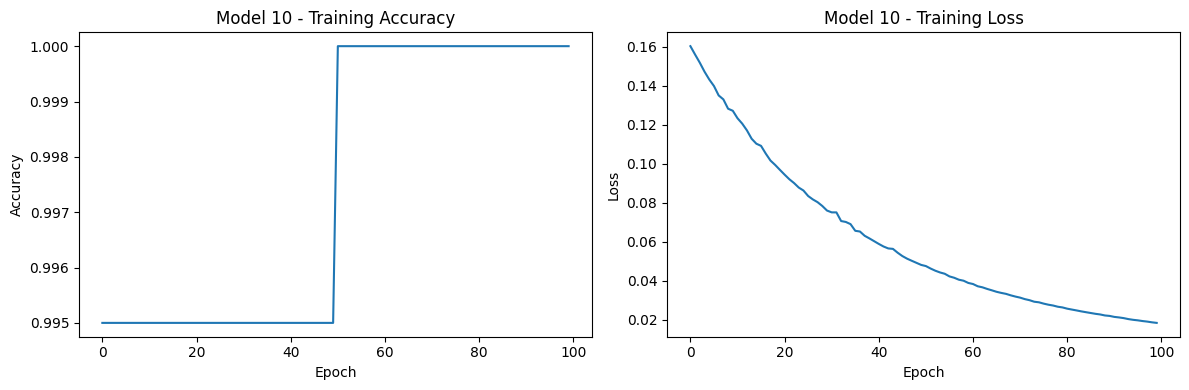

In [48]:
accuracy9 = (
    history9.history['accuracy'] +
    history9_more.history['accuracy']
)

loss9 = (
    history9.history['loss'] +
    history9_more.history['loss']
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(accuracy9)
plt.title('Model 9 - Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss9)
plt.title('Model 9 - Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()